In [1]:
# ============================================================
# Experiment:
# Full Fine-Tuning vs LoRA using Hugging Face Trainer and PEFT
# ============================================================

# ------------------------------------------------------------
# Step 1: Install Required Libraries
# ------------------------------------------------------------
# Run this cell once if the libraries are not installed.
# !pip install -q transformers datasets peft accelerate torch


# ------------------------------------------------------------
# Step 2: Import Libraries
# ------------------------------------------------------------

import time
import torch
import matplotlib.pyplot as plt

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

from datasets import Dataset

from peft import (
    LoraConfig,
    get_peft_model,
    TaskType
)


ModuleNotFoundError: No module named 'torch'

In [1]:
# ------------------------------------------------------------
# Step 3: Select Pretrained Model
# ------------------------------------------------------------

model_name = "distilbert-base-uncased"

print("Pretrained Model:", model_name)
print("PyTorch Version:", torch.__version__)

Pretrained Model: distilbert-base-uncased


NameError: name 'torch' is not defined

In [ ]:
# ------------------------------------------------------------
# Step 4: Create a Small Custom Dataset
# ------------------------------------------------------------

texts = [
    "This movie was absolutely wonderful and inspiring",
    "I loved every moment of this film",
    "The acting was superb and the story touching",
    "A truly great and memorable experience",

    "This movie was boring and way too long",
    "I hated the plot and the characters",
    "The acting was terrible and the story dull",
    "A disappointing and forgettable experience"
]

# 1 = Positive
# 0 = Negative

labels = [
    1, 1, 1, 1,
    0, 0, 0, 0
]

dataset = Dataset.from_dict({
    "text": texts,
    "label": labels
})

# Split into training and test sets
dataset = dataset.train_test_split(
    test_size=0.25,
    seed=42
)

print("\nDataset:")
print(dataset)



Dataset:
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 6
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2
    })
})


In [ ]:
# ------------------------------------------------------------
# Step 5: Tokenization
# ------------------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(model_name)


def tokenize_function(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        padding=False
    )


tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("\nTokenized Dataset:")
print(tokenized_dataset)


Map:   0%|          | 0/6 [00:00<?, ? examples/s]

Map:   0%|          | 0/2 [00:00<?, ? examples/s]


Tokenized Dataset:
DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 6
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2
    })
})


In [ ]:
# ============================================================
# PART A: FULL FINE-TUNING
# ============================================================

# ------------------------------------------------------------
# Step 6: Load Fresh Pretrained Model
# ------------------------------------------------------------

model_full = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

print("\n===== FULL FINE-TUNING =====")


# ------------------------------------------------------------
# Step 7: Count Parameters
# ------------------------------------------------------------

total_params_full = sum(
    p.numel()
    for p in model_full.parameters()
)

trainable_params_full = sum(
    p.numel()
    for p in model_full.parameters()
    if p.requires_grad
)

print(
    "Total parameters:",
    f"{total_params_full:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_params_full:,}"
)



Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



===== FULL FINE-TUNING =====
Total parameters: 66,955,010
Trainable parameters: 66,955,010


In [ ]:
# ------------------------------------------------------------
# Step 8: Training Arguments for Full Fine-Tuning
# ------------------------------------------------------------

args_full = TrainingArguments(
    output_dir="./results_full",
    num_train_epochs=3,
    per_device_train_batch_size=2,
    seed=42
)


# ------------------------------------------------------------
# Step 9: Create Trainer for Full Fine-Tuning
# ------------------------------------------------------------

trainer_full = Trainer(
    model=model_full,
    args=args_full,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    data_collator=data_collator
)


# ------------------------------------------------------------
# Step 10: Train Full Model
# ------------------------------------------------------------

start_time_full = time.time()

result_full = trainer_full.train()

full_training_time = time.time() - start_time_full

print("\nFull Fine-Tuning Completed.")

print(
    "Final Training Loss:",
    f"{result_full.training_loss:.4f}"
)

print(
    "Training Time:",
    f"{full_training_time:.2f} seconds"
)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
1,0.587174
2,0.843621
3,0.667610
4,0.722402
5,0.647067
6,0.690204
7,0.644498
8,0.647136
9,0.629161


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Full Fine-Tuning Completed.
Final Training Loss: 0.6754
Training Time: 14.96 seconds


In [ ]:
# ------------------------------------------------------------
# Step 11: Evaluate Full Fine-Tuned Model
# ------------------------------------------------------------

full_eval = trainer_full.evaluate()

print("\nFull Fine-Tuning Evaluation Loss:",
      f"{full_eval['eval_loss']:.4f}")


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Step
0.629161,0.701035,9



Full Fine-Tuning Evaluation Loss: 0.7010


In [ ]:
# ============================================================
# PART B: LoRA FINE-TUNING
# ============================================================

# ------------------------------------------------------------
# Step 12: Load Another Fresh Pretrained Model
# ------------------------------------------------------------

model_lora_base = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

print("\n===== LoRA FINE-TUNING =====")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



===== LoRA FINE-TUNING =====


In [ ]:
# ------------------------------------------------------------
# Step 13: Configure LoRA
# ------------------------------------------------------------

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["q_lin", "v_lin"]
)


In [ ]:

# ------------------------------------------------------------
# Step 14: Apply LoRA to the Model
# ------------------------------------------------------------

model_lora = get_peft_model(
    model_lora_base,
    lora_config
)

print("\nLoRA Trainable Parameters:")
model_lora.print_trainable_parameters()



LoRA Trainable Parameters:
trainable params: 739,586 || all params: 67,694,596 || trainable%: 1.0925


In [ ]:
# ------------------------------------------------------------
# Step 15: Count LoRA Parameters
# ------------------------------------------------------------

total_params_lora = sum(
    p.numel()
    for p in model_lora.parameters()
)

trainable_params_lora = sum(
    p.numel()
    for p in model_lora.parameters()
    if p.requires_grad
)

lora_trainable_percentage = (
    100 * trainable_params_lora / total_params_lora
)

print(
    "Total parameters:",
    f"{total_params_lora:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_params_lora:,}"
)

print(
    "Percentage trainable:",
    f"{lora_trainable_percentage:.2f}%"
)


Total parameters: 67,694,596
Trainable parameters: 739,586
Percentage trainable: 1.09%


In [ ]:
# ------------------------------------------------------------
# Step 16: Training Arguments for LoRA
# ------------------------------------------------------------

args_lora = TrainingArguments(
    output_dir="./results_lora",
    num_train_epochs=3,
    per_device_train_batch_size=2,
    logging_steps=1,
    report_to="none",
    seed=42
)


# ------------------------------------------------------------
# Step 17: Create Trainer for LoRA
# ------------------------------------------------------------

trainer_lora = Trainer(
    model=model_lora,
    args=args_lora,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    data_collator=data_collator
)


# ------------------------------------------------------------
# Step 18: Train LoRA Model
# ------------------------------------------------------------

start_time_lora = time.time()

result_lora = trainer_lora.train()

lora_training_time = time.time() - start_time_lora

print("\nLoRA Fine-Tuning Completed.")

print(
    "Final Training Loss:",
    f"{result_lora.training_loss:.4f}"
)

print(
    "Training Time:",
    f"{lora_training_time:.2f} seconds"
)



[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


Step,Training Loss
1,0.575511
2,0.913067
3,0.687339
4,0.701593
5,0.713990
6,0.692452
7,0.737862
8,0.675349
9,0.654305



LoRA Fine-Tuning Completed.
Final Training Loss: 0.7057
Training Time: 1.90 seconds


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Step
0.654305,0.708716,9



LoRA Evaluation Loss: 0.7087

Full Fine-Tuning Losses:
[0.5871738195419312, 0.8436208963394165, 0.6676101684570312, 0.7224017381668091, 0.6470668911933899, 0.6902036666870117, 0.6444977521896362, 0.6471355557441711, 0.6291607022285461]

LoRA Losses:
[0.5755109786987305, 0.9130672812461853, 0.6873387098312378, 0.7015925645828247, 0.7139904499053955, 0.692452073097229, 0.7378615140914917, 0.6753490567207336, 0.6543045043945312]


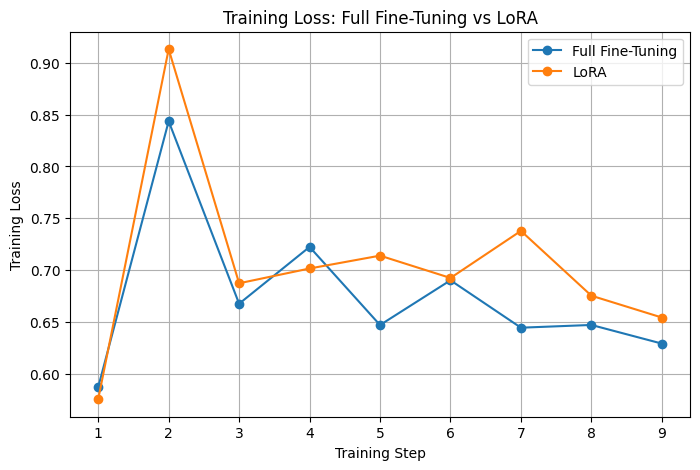

In [ ]:

# ------------------------------------------------------------
# Step 19: Evaluate LoRA Model
# ------------------------------------------------------------

lora_eval = trainer_lora.evaluate()

print("\nLoRA Evaluation Loss:",
      f"{lora_eval['eval_loss']:.4f}")


# ============================================================
# PART C: TRAINING LOSS COMPARISON
# ============================================================

# ------------------------------------------------------------
# Step 20: Extract Training Losses
# ------------------------------------------------------------

def get_training_losses(trainer):

    losses = []

    for entry in trainer.state.log_history:

        if "loss" in entry:
            losses.append(entry["loss"])

    return losses


full_losses = get_training_losses(trainer_full)
lora_losses = get_training_losses(trainer_lora)

print("\nFull Fine-Tuning Losses:")
print(full_losses)

print("\nLoRA Losses:")
print(lora_losses)


# ------------------------------------------------------------
# Step 21: Plot Training Loss Comparison
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(full_losses) + 1),
    full_losses,
    marker="o",
    label="Full Fine-Tuning"
)

plt.plot(
    range(1, len(lora_losses) + 1),
    lora_losses,
    marker="o",
    label="LoRA"
)

plt.xlabel("Training Step")
plt.ylabel("Training Loss")

plt.title(
    "Training Loss: Full Fine-Tuning vs LoRA"
)

plt.legend()
plt.grid(True)

plt.show()




In [ ]:
# ============================================================
# PART D: FINAL COMPARISON
# ============================================================

# ------------------------------------------------------------
# Step 22: Compare Results
# ------------------------------------------------------------

print("\n")
print("=" * 55)
print("       FULL FINE-TUNING vs LoRA")
print("=" * 55)

print(
    "\nTrainable Parameters:"
)

print(
    "Full Fine-Tuning :",
    f"{trainable_params_full:,}"
)

print(
    "LoRA             :",
    f"{trainable_params_lora:,}"
)

print(
    "\nPercentage of Parameters Trained by LoRA:",
    f"{lora_trainable_percentage:.2f}%"
)

print(
    "\nFinal Training Loss:"
)

print(
    "Full Fine-Tuning :",
    f"{result_full.training_loss:.4f}"
)

print(
    "LoRA             :",
    f"{result_lora.training_loss:.4f}"
)

print(
    "\nEvaluation Loss:"
)

print(
    "Full Fine-Tuning :",
    f"{full_eval['eval_loss']:.4f}"
)

print(
    "LoRA             :",
    f"{lora_eval['eval_loss']:.4f}"
)

print(
    "\nTraining Time:"
)

print(
    "Full Fine-Tuning :",
    f"{full_training_time:.2f} seconds"
)

print(
    "LoRA             :",
    f"{lora_training_time:.2f} seconds"
)

print("=" * 55)


# ============================================================
# END OF PROGRAM
# ================================================



       FULL FINE-TUNING vs LoRA

Trainable Parameters:
Full Fine-Tuning : 66,955,010
LoRA             : 739,586

Percentage of Parameters Trained by LoRA: 1.09%

Final Training Loss:
Full Fine-Tuning : 0.6754
LoRA             : 0.7057

Evaluation Loss:
Full Fine-Tuning : 0.7010
LoRA             : 0.7087

Training Time:
Full Fine-Tuning : 14.96 seconds
LoRA             : 1.90 seconds
